# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Muhamad Nafi Mulyo | 5054251005 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sns.set_theme(style="whitegrid")
FEATURES = ["Annual Income (k$)", "Spending Score (1-100)"]

In [2]:
df = pd.read_csv("Mall_Customers.csv")
display(df.head())
print("Baris, kolom :", df.shape)
print("\nTipe data:"); print(df.dtypes)
display(df.describe().round(2))
print("Missing value per kolom:"); print(df.isna().sum())
print("\nBaris duplikat:", df.duplicated().sum())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Baris, kolom : (200, 5)

Tipe data:
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00,200.00
mean,100.50,38.85,60.56,50.20
std,57.88,13.97,26.26,25.82
min,1.00,18.00,15.00,1.00
25%,50.75,28.75,41.50,34.75
50%,100.50,36.00,61.50,50.00
75%,150.25,49.00,78.00,73.00
max,200.00,70.00,137.00,99.00


Missing value per kolom:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Baris duplikat: 0


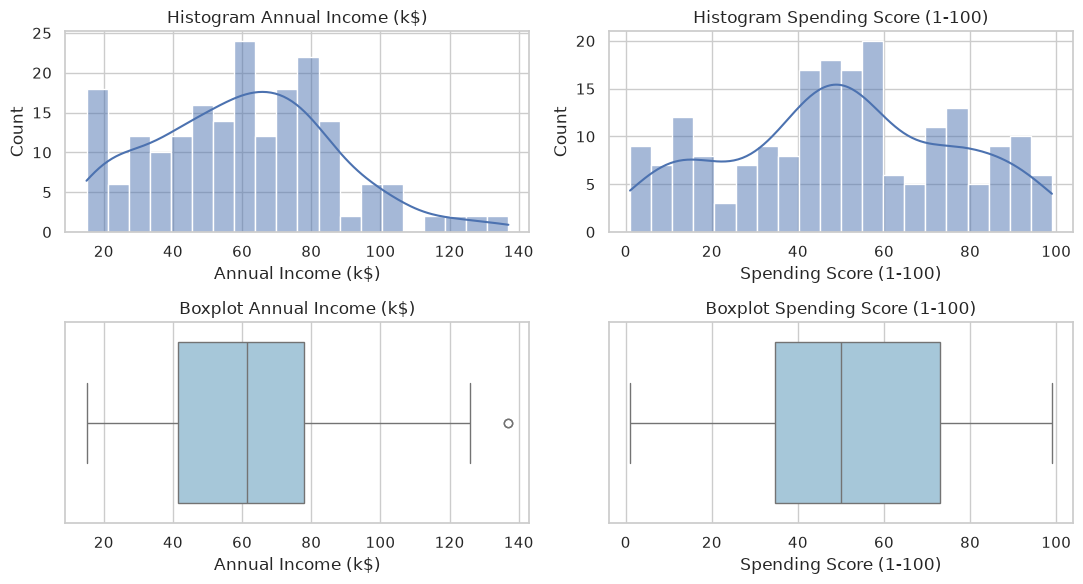

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for i, col in enumerate(FEATURES):
    sns.histplot(df[col], bins=20, kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"Histogram {col}")
    sns.boxplot(x=df[col], ax=axes[1, i], color="#9ecae1")
    axes[1, i].set_title(f"Boxplot {col}")
plt.tight_layout(); plt.show()

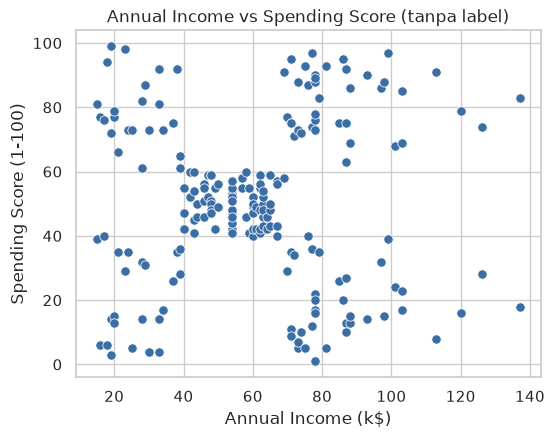

In [4]:
plt.figure(figsize=(6, 4.5))
sns.scatterplot(data=df, x=FEATURES[0], y=FEATURES[1], color="#3b6ea5", s=45)
plt.title("Annual Income vs Spending Score (tanpa label)")
plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

**Jawaban:**

- **Missing value / duplikat:** tidak ada. Semua kolom lengkap (200 baris) dan jumlah baris duplikat = 0.
- **Rentang:** `Annual Income` 15-137 k$ (mean 60,56; median 61,5) dengan distribusi sedikit condong ke kanan dan satu outlier di boxplot (sekitar 137 k$). `Spending Score` 1-99 (mean 50,2; median 50) dengan distribusi relatif simetris, beberapa puncak, dan tanpa outlier.
- **Kelompok:** ya, scatter plot memperlihatkan sekitar **5 kelompok**: satu kelompok padat di tengah (income sekitar 40-70, skor sekitar 40-60) dan empat kelompok di keempat sudut (income rendah/tinggi x skor rendah/tinggi).

# 2. Preprocessing

In [5]:
# Tidak ada missing value maupun duplikat, tetapi tetap ditangani agar kode aman dijalankan ulang.
df = df.dropna().drop_duplicates().reset_index(drop=True)

# CustomerID dan Gender tidak ikut menjadi fitur: hanya dua fitur numerik yang dipakai.
X = df[FEATURES].copy()
print(X.shape)
display(X.head())

(200, 2)


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [6]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
display(X_scaled.head())
display(X_scaled.describe().round(3))

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


,Annual Income (k$),Spending Score (1-100)
count,200.000,200.000
mean,-0.000,-0.000
std,1.003,1.003
min,-1.739,-1.910
25%,-0.728,-0.600
50%,0.036,-0.008
75%,0.666,0.885
max,2.918,1.894


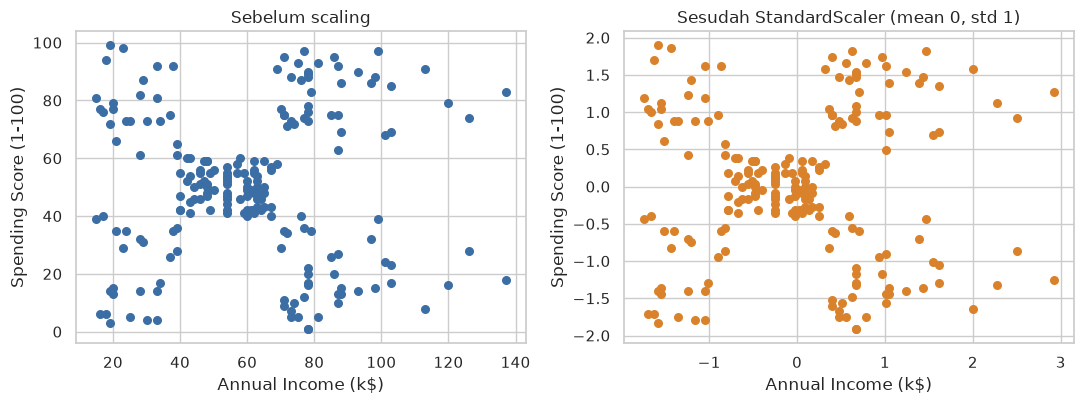

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].scatter(X.iloc[:, 0], X.iloc[:, 1], s=30, color="#3b6ea5")
axes[0].set(title="Sebelum scaling", xlabel=X.columns[0], ylabel=X.columns[1])
axes[1].scatter(X_scaled.iloc[:, 0], X_scaled.iloc[:, 1], s=30, color="#d9822b")
axes[1].set(title="Sesudah StandardScaler (mean 0, std 1)", xlabel=X.columns[0], ylabel=X.columns[1])
plt.tight_layout(); plt.show()

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

**Jawaban:**

**Alasan pemilihan fitur:** dua fitur ini dipilih karena menggambarkan perilaku pelanggan secara langsung (kemampuan finansial dan kecenderungan berbelanja), keduanya numerik, dan hasilnya bisa digambar pada bidang 2D sehingga setiap cluster mudah ditafsirkan. `CustomerID` tidak dipakai karena hanya nomor urut/identitas: nilainya tidak memuat informasi tentang kemiripan pelanggan, sehingga jika dimasukkan akan menambah jarak yang tidak bermakna dan menyesatkan algoritma. `Gender` tidak dipakai dalam model utama (sesuai instruksi), hanya boleh untuk interpretasi tambahan.

**Mengapa scaling penting:** DBSCAN (parameter `eps`), BIRCH (parameter `threshold`), dan GMM (kovarians) semuanya bergantung pada jarak atau sebaran data. Tanpa scaling, fitur dengan satuan/rentang yang besar mendominasi jarak (mis. jika pendapatan dalam dolar penuh, skor 1-100 hampir tidak berpengaruh). Setelah `StandardScaler`, kedua fitur memiliki mean 0 dan std 1, sehingga `eps=0,4` berarti 0,4 simpangan baku, berlaku sama untuk kedua sumbu. Pada dataset ini, std kedua fitur sebenarnya mirip (26,3 vs 25,8), sehingga bentuk scatter sebelum dan sesudah scaling hampir sama (hanya skalanya yang berubah). Scaling di sini lebih berfungsi sebagai praktik yang aman dan membuat parameter `eps`/`threshold` dapat ditafsirkan, bukan karena perbedaan skala yang ekstrem.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [8]:
dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)
print("Label unik:", sorted(set(labels_dbscan)))

Label unik: [np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


In [9]:
print("Anggota per label (-1 = noise):")
print(pd.Series(labels_dbscan).value_counts().sort_index())
n_clusters_db = len(set(labels_dbscan) - {-1})
n_noise_db = int((labels_dbscan == -1).sum())
print(f"\nJumlah cluster (tanpa noise): {n_clusters_db}")
print(f"Jumlah noise               : {n_noise_db}")

Anggota per label (-1 = noise):
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64

Jumlah cluster (tanpa noise): 7
Jumlah noise               : 35


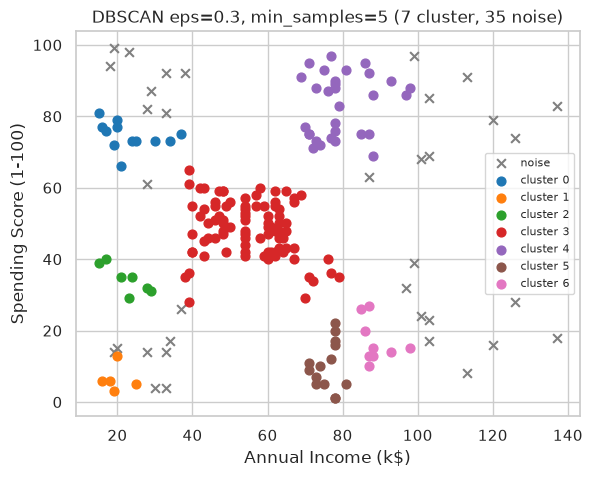

In [10]:
def plot_clusters(ax, data, labels, title):
    """Scatter plot per cluster; noise (label -1) digambar abu-abu dengan tanda x."""
    palette = sns.color_palette("tab10", 10)
    for lab in sorted(set(labels)):
        m = labels == lab
        if lab == -1:
            ax.scatter(data.iloc[m, 0], data.iloc[m, 1], c="gray", marker="x", s=40, label="noise")
        else:
            ax.scatter(data.iloc[m, 0], data.iloc[m, 1], color=palette[lab % 10], s=40, label=f"cluster {lab}")
    ax.set(title=title, xlabel=data.columns[0], ylabel=data.columns[1])
    ax.legend(fontsize=8, loc="best")

fig, ax = plt.subplots(figsize=(6.5, 5))
plot_clusters(ax, X, labels_dbscan, f"DBSCAN eps=0.3, min_samples=5 ({n_clusters_db} cluster, {n_noise_db} noise)")
plt.show()

In [11]:
rows = []
for eps in [0.2, 0.3, 0.4, 0.5, 0.6]:
    for ms in [3, 5, 8]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        mask = lab != -1
        k = len(set(lab) - {-1})
        # silhouette hanya valid jika >=2 cluster; dihitung pada titik non-noise
        sil = silhouette_score(X_scaled[mask], lab[mask]) if k >= 2 else np.nan
        rows.append({"eps": eps, "min_samples": ms, "n_cluster": k,
                     "n_noise": int((~mask).sum()), "silhouette (non-noise)": round(sil, 3)})
dbscan_table = pd.DataFrame(rows)
display(dbscan_table)

,eps,min_samples,n_cluster,n_noise,silhouette (non-noise)
0,0.2,3,13,44,0.470
1,0.2,5,7,77,0.586
2,0.2,8,2,116,0.603
3,0.3,3,9,14,0.472
4,0.3,5,7,35,0.524
5,0.3,8,5,72,0.593
6,0.4,3,4,10,0.395
7,0.4,5,4,15,0.478
8,0.4,8,5,25,0.549
9,0.5,3,2,7,0.389


### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

**Jawaban:**

- **Pengaruh `eps`:** pada `min_samples=5`, menaikkan `eps` dari 0,2 ke 0,6 menurunkan noise secara konsisten (77 → 35 → 15 → 8 → 5) dan jumlah cluster menurun karena cluster-cluster berdekatan menyatu (7 → 7 → 4 → 2 → 1). `eps` kecil memecah kelompok besar menjadi banyak cluster kecil dan menandai banyak titik sebagai noise; `eps` besar menggabungkan semuanya.
- **Pengaruh `min_samples`:** pada `eps` yang sama, menaikkan `min_samples` membuat syarat core point lebih ketat sehingga **noise bertambah** (eps=0,3: 14 → 35 → 72 untuk min_samples 3 → 5 → 8) dan cluster kecil hilang atau tidak terbentuk (eps=0,2: 13 → 7 → 2 cluster).
- **Kombinasi bermasalah:** `eps=0,6` (semua `min_samples`) hanya menghasilkan **1 cluster besar**, sehingga segmen tidak terpisah. Sebaliknya `eps=0,2, min_samples=8` menghasilkan hanya 2 cluster dengan **116 titik noise (58%)**. Perhatikan bahwa silhouette tertinggi (0,603) justru ada pada kombinasi terakhir ini karena silhouette hanya dihitung pada titik non-noise, jadi nilai tertinggi tidak otomatis berarti paling baik. Karena itu `eps=0,4, min_samples=8` (5 cluster, 25 noise, silhouette 0,549) dipilih sebagai konfigurasi yang paling masuk akal.

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [12]:
birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(X_scaled)
print("Jumlah subcluster di pohon CF:", len(birch.subcluster_centers_))

Jumlah subcluster di pohon CF: 10


In [13]:
print("Anggota per cluster BIRCH:")
print(pd.Series(labels_birch).value_counts().sort_index())
print("Jumlah cluster:", len(set(labels_birch)))

Anggota per cluster BIRCH:
0     36
1    109
2      8
3     25
4     22
Name: count, dtype: int64
Jumlah cluster: 5


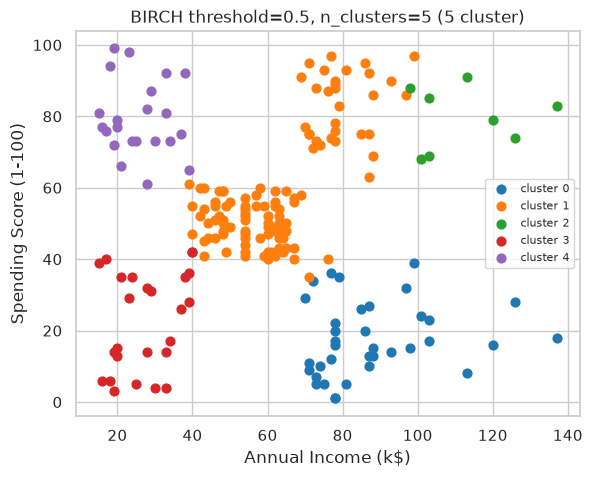

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 5))
plot_clusters(ax, X, labels_birch, f"BIRCH threshold=0.5, n_clusters=5 ({len(set(labels_birch))} cluster)")
plt.show()

In [15]:
rows = []
for thr in [0.3, 0.5, 0.7, 1.0]:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # peringatan jika subcluster < n_clusters
        b = Birch(threshold=thr, n_clusters=5).fit(X_scaled)
    lab = b.labels_
    k = len(set(lab))
    rows.append({"threshold": thr, "n_subcluster": len(b.subcluster_centers_), "n_cluster": k,
                 "silhouette": round(silhouette_score(X_scaled, lab), 3) if k >= 2 else np.nan})
display(pd.DataFrame(rows))

# Pengaruh n_clusters pada threshold tetap (0.5)
rows = []
for k_ in [3, 4, 5, 6, 7]:
    lab = Birch(threshold=0.5, n_clusters=k_).fit_predict(X_scaled)
    rows.append({"threshold": 0.5, "n_clusters": k_, "silhouette": round(silhouette_score(X_scaled, lab), 3)})
display(pd.DataFrame(rows))
# n_clusters=None: hanya subcluster dari pohon, tanpa langkah penggabungan akhir
lab_none = Birch(threshold=0.5, n_clusters=None).fit_predict(X_scaled)
print("n_clusters=None, threshold=0.5 -> jumlah cluster =", len(set(lab_none)))

,threshold,n_subcluster,n_cluster,silhouette
0,0.3,23,5,0.478
1,0.5,10,5,0.414
2,0.7,6,5,0.421
3,1.0,4,4,0.389


,threshold,n_clusters,silhouette
0,0.5,3,0.338
1,0.5,4,0.352
2,0.5,5,0.414
3,0.5,6,0.390
4,0.5,7,0.522


n_clusters=None, threshold=0.5 -> jumlah cluster = 10


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

**Jawaban:**

- **Pengaruh `threshold`:** semakin besar `threshold`, semakin sedikit subcluster di pohon CF (0,3 → 23, 0,5 → 10, 0,7 → 6, 1,0 → 4). Pada `threshold=1,0` subcluster (4) lebih sedikit daripada `n_clusters=5`, sehingga hasil akhir hanya 4 cluster (sklearn memberi ConvergenceWarning; peringatannya disembunyikan di sel eksperimen). Silhouette pada `n_clusters=5`: 0,478 / 0,414 / 0,421 / 0,389, jadi `threshold` kecil memberi ringkasan yang lebih halus sebelum digabungkan.
- **BIRCH vs DBSCAN untuk titik terpencil:** DBSCAN menandai titik jauh sebagai noise (label -1) dan tidak memasukkannya ke cluster mana pun. BIRCH tidak punya label noise: setiap titik pasti masuk suatu subcluster. Titik terpencil bisa ikut menyatu ke cluster terdekat atau membentuk cluster kecil sendiri. Pada model akhir (`threshold=0,3`), muncul cluster berisi hanya 3 pelanggan berpendapatan sangat tinggi (median 126 k$), yaitu titik terpencil yang menjadi "cluster", bukan noise.
- **Pengaruh `n_clusters`:** ya, hasilnya berubah. Pada `threshold=0,5`, silhouette untuk `n_clusters` 3, 4, 5, 6, 7 adalah 0,338; 0,352; 0,414; 0,390; 0,522. Dengan `n_clusters=None` BIRCH hanya mengembalikan 10 subcluster dari pohon tanpa penggabungan akhir. Nilai k=7 punya silhouette tertinggi, tetapi nilai tinggi tidak otomatis berarti segmentasi yang bermakna (kemungkinan memisahkan kelompok kecil atau titik terpencil).

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [16]:
gmm = GaussianMixture(n_components=5, covariance_type="full", random_state=42)
gmm.fit(X_scaled)                     # EM berjalan di dalam fit()
labels_gmm = gmm.predict(X_scaled)
print("EM konvergen:", gmm.converged_, "| iterasi:", gmm.n_iter_)
print("Bobot komponen:", gmm.weights_.round(3))

EM konvergen: True | iterasi: 5
Bobot komponen: [0.413 0.197 0.104 0.166 0.121]


In [17]:
print("Anggota per cluster GMM:")
print(pd.Series(labels_gmm).value_counts().sort_index())
proba = gmm.predict_proba(X_scaled)
display(pd.DataFrame(proba[:8], columns=[f"komp_{i}" for i in range(5)]).round(3))
max_p = proba.max(axis=1)
print(f"Titik dengan probabilitas tertinggi < 0.90: {(max_p < 0.90).sum()} dari {len(max_p)}")
print(f"Titik dengan probabilitas tertinggi < 0.70: {(max_p < 0.70).sum()}")
display(X[max_p < 0.90].assign(max_prob=max_p[max_p < 0.90].round(3)).head(10))

Anggota per cluster GMM:
0    84
1    39
2    21
3    33
4    23
Name: count, dtype: int64


,komp_0,komp_1,komp_2,komp_3,komp_4
0,0.0,0.0,0.001,0.0,0.999
1,0.0,0.0,1.000,0.0,0.000
2,0.0,0.0,0.000,0.0,1.000
3,0.0,0.0,1.000,0.0,0.000
4,0.0,0.0,0.002,0.0,0.998
5,0.0,0.0,1.000,0.0,0.000
6,0.0,0.0,0.000,0.0,1.000
7,0.0,0.0,1.000,0.0,0.000


Titik dengan probabilitas tertinggi < 0.90: 8 dari 200
Titik dengan probabilitas tertinggi < 0.70: 4


,Annual Income (k$),Spending Score (1-100),max_prob
27,28,61,0.675
45,39,65,0.822
47,40,47,0.891
48,40,42,0.611
49,40,42,0.611
55,43,41,0.796
124,70,29,0.503
160,79,35,0.772


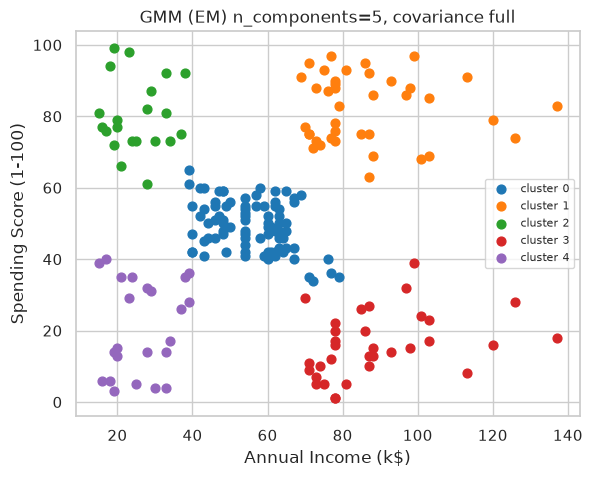

In [18]:
fig, ax = plt.subplots(figsize=(6.5, 5))
plot_clusters(ax, X, labels_gmm, "GMM (EM) n_components=5, covariance full")
plt.show()

,n_components,silhouette,BIC
0,2,0.379,1153.9
1,3,0.430,1151.7
2,4,0.413,1103.8
3,5,0.554,1058.7
4,6,0.517,1074.7
5,7,0.509,1087.3
6,8,0.430,1102.4


Silhouette tertinggi di k = 5
BIC terendah di k         = 5


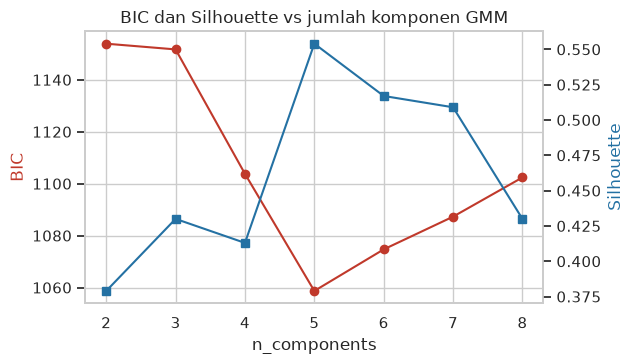

In [19]:
rows = []
for k in range(2, 9):
    g = GaussianMixture(n_components=k, covariance_type="full", random_state=42).fit(X_scaled)
    lab = g.predict(X_scaled)
    rows.append({"n_components": k, "silhouette": round(silhouette_score(X_scaled, lab), 3),
                 "BIC": round(g.bic(X_scaled), 1)})
gmm_table = pd.DataFrame(rows)
display(gmm_table)
print("Silhouette tertinggi di k =", gmm_table.loc[gmm_table["silhouette"].idxmax(), "n_components"])
print("BIC terendah di k         =", gmm_table.loc[gmm_table["BIC"].idxmin(), "n_components"])

fig, ax1 = plt.subplots(figsize=(6.5, 3.8))
ax1.plot(gmm_table["n_components"], gmm_table["BIC"], "o-", color="#c0392b"); ax1.set_ylabel("BIC", color="#c0392b")
ax2 = ax1.twinx(); ax2.plot(gmm_table["n_components"], gmm_table["silhouette"], "s-", color="#2471a3")
ax2.set_ylabel("Silhouette", color="#2471a3"); ax2.grid(False)
ax1.set(xlabel="n_components", title="BIC dan Silhouette vs jumlah komponen GMM")
plt.tight_layout(); plt.show()

### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

**Jawaban:**

- **Probabilitas keanggotaan:** `predict_proba` memberi peluang setiap titik berasal dari masing-masing komponen Gaussian (jumlahnya 1); label cluster diambil dari komponen dengan peluang terbesar (*soft clustering*). Sebagian besar titik hampir pasti (peluang sekitar 1,0), tetapi **8 titik** punya peluang tertinggi di bawah 0,90 dan 4 titik di bawah 0,70. Yang paling tidak pasti adalah titik (income 70, skor 29) dengan peluang tertinggi hanya 0,503; titik-titik seperti ini berada di perbatasan dua cluster.
- **Perubahan `n_components`:** BIC turun dari 1153,9 (k=2) ke 1058,7 (k=5), lalu naik lagi (1074,7 pada k=6 dan 1102,4 pada k=8); silhouette tertinggi juga di k=5 (0,554). Terlalu sedikit komponen menggabungkan kelompok berbeda (underfit), sedangkan terlalu banyak memecah kelompok yang sama (overfit, penalti kompleksitas BIC naik).
- **Mengapa k ditentukan di awal:** `n_components` adalah bagian dari struktur model (jumlah Gaussian yang dicampur dan jumlah parameter yang harus diestimasi oleh EM), sehingga harus ditetapkan sebelum EM berjalan. Nilainya bisa dipilih dengan membandingkan beberapa model, misalnya lewat BIC.
- **Silhouette tertinggi vs BIC terendah:** pada dataset ini **ya, keduanya sama-sama jatuh di k=5**. Ini tidak selalu terjadi; kedua kriteria mengukur hal berbeda (silhouette mengukur keterpisahan cluster, BIC mengukur kecocokan model terhadap data dengan penalti kompleksitas).

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [20]:
def evaluate(data, labels, drop_noise=False):
    """Hitung 3 metrik internal. Noise (-1) dibuang jika drop_noise=True."""
    data, labels = np.asarray(data), np.asarray(labels)
    if drop_noise:
        keep = labels != -1
        data, labels = data[keep], labels[keep]
    k = len(set(labels))
    # valid hanya jika >= 2 cluster dan k < jumlah titik
    if k < 2 or k >= len(data):
        return {"silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}
    return {"silhouette": silhouette_score(data, labels),
            "davies_bouldin": davies_bouldin_score(data, labels),
            "calinski_harabasz": calinski_harabasz_score(data, labels)}

In [21]:
# Model terbaik hasil eksperimen sebelumnya.
# DBSCAN dipilih dengan eps=0.4, min_samples=8: 5 cluster dengan noise yang moderat
# (konfigurasi silhouette tertinggi hanya menghasilkan 2 cluster dengan >100 noise).
labels_db_best = DBSCAN(eps=0.4, min_samples=8).fit_predict(X_scaled)
labels_bi_best = Birch(threshold=0.3, n_clusters=5).fit_predict(X_scaled)
labels_gm_best = GaussianMixture(n_components=5, covariance_type="full", random_state=42).fit_predict(X_scaled)

models = {"DBSCAN (eps=0.4, ms=8)": (labels_db_best, True),
          "BIRCH (thr=0.3, k=5)": (labels_bi_best, False),
          "GMM/EM (k=5, full)": (labels_gm_best, False)}
rows = []
for name, (lab, drop) in models.items():
    rows.append({"model": name,
                 "n_cluster": len(set(lab) - {-1}),
                 "n_noise": int((lab == -1).sum()) if drop else 0,
                 **evaluate(X_scaled, lab, drop_noise=drop)})
summary = pd.DataFrame(rows).set_index("model")
display(summary.round(3))

,n_cluster,n_noise,silhouette,davies_bouldin,calinski_harabasz
model,,,,,
"DBSCAN (eps=0.4, ms=8)",5,25,0.549,0.501,222.065
"BIRCH (thr=0.3, k=5)",5,0,0.478,0.648,144.013
"GMM/EM (k=5, full)",5,0,0.554,0.576,244.940


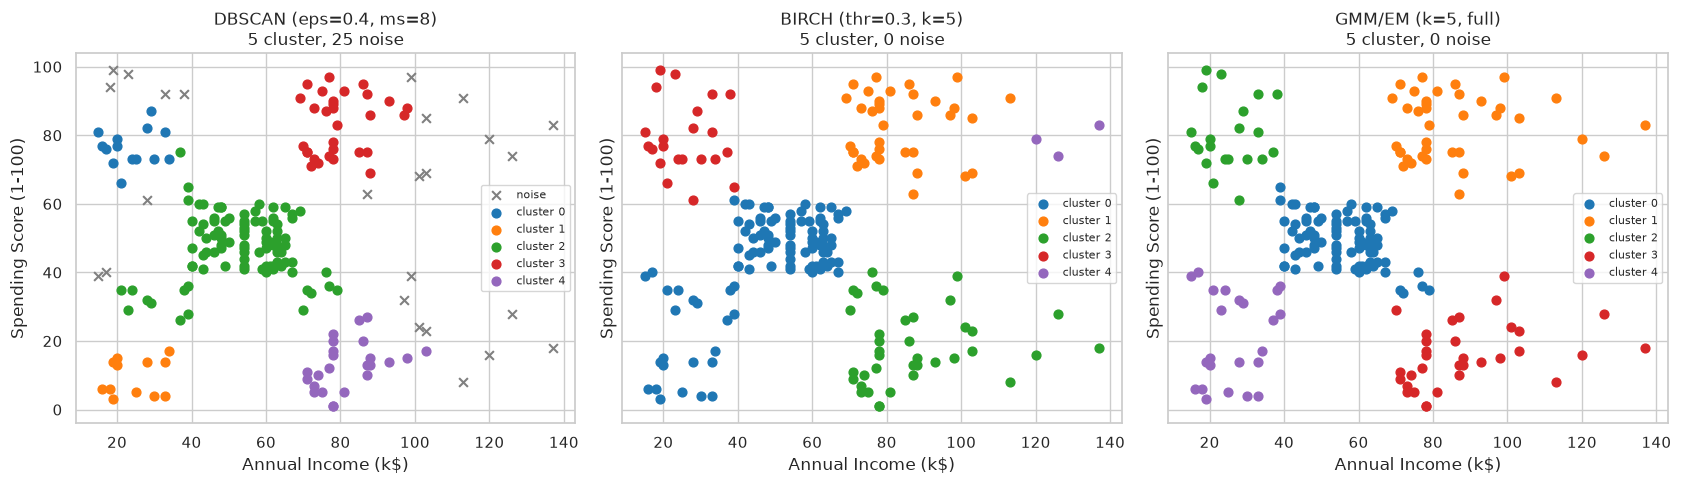

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, (name, (lab, _)) in zip(axes, models.items()):
    n_noise = int((lab == -1).sum())
    plot_clusters(ax, X, lab, f"{name}\n{len(set(lab) - {-1})} cluster, {n_noise} noise")
plt.tight_layout(); plt.show()

In [23]:
for name, (lab, _) in models.items():
    prof = (X.assign(cluster=lab).groupby("cluster")
              .agg(jumlah=(FEATURES[0], "size"),
                   income_median=(FEATURES[0], "median"), income_mean=(FEATURES[0], "mean"),
                   spending_median=(FEATURES[1], "median"), spending_mean=(FEATURES[1], "mean")).round(1))
    print(f"=== {name} ===" + ("  (cluster -1 = noise)" if -1 in lab else ""))
    display(prof)

=== DBSCAN (eps=0.4, ms=8) ===  (cluster -1 = noise)


,jumlah,income_median,income_mean,spending_median,spending_mean
cluster,,,,,
-1,25,101.0,83.0,68.0,60.5
0,14,22.5,23.6,76.5,76.4
1,12,22.5,24.6,9.5,9.6
2,95,54.0,53.3,48.0,47.8
3,30,78.0,79.5,86.0,83.1
4,24,78.0,81.9,13.0,13.0


=== BIRCH (thr=0.3, k=5) ===


,jumlah,income_median,income_mean,spending_median,spending_mean
cluster,,,,,
0,101,50.0,48.2,47.0,43.4
1,36,78.0,83.1,85.5,82.4
2,38,80.0,87.0,16.5,18.6
3,22,24.5,25.7,77.0,79.4
4,3,126.0,127.7,79.0,78.7


=== GMM/EM (k=5, full) ===


,jumlah,income_median,income_mean,spending_median,spending_mean
cluster,,,,,
0,84,55.5,55.6,49.5,49.4
1,39,79.0,86.5,83.0,82.1
2,21,24.0,25.1,77.0,80.0
3,33,86.0,88.8,15.0,16.0
4,23,25.0,26.3,17.0,20.9


### Ringkasan Perbandingan

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak; jumlah cluster muncul dari `eps` dan `min_samples` | Opsional: `n_clusters` bisa diberikan, atau `None` untuk hanya subcluster dari pohon | Ya, `n_components` harus ditentukan (bisa dipilih dengan BIC) |
| Dapat memberi label noise secara eksplisit? | Ya, label -1 (25 titik pada model akhir) | Tidak | Tidak secara eksplisit, tetapi probabilitas rendah menandai titik yang tidak pasti |
| Parameter yang paling memengaruhi hasil | `eps` (paling sensitif) dan `min_samples` | `threshold` dan `n_clusters` | `n_components` dan `covariance_type` |
| Bentuk cluster yang dapat dimodelkan | Bentuk bebas (berbasis kepadatan) | Cenderung bulat/cembung (berbasis centroid) | Elips (Gaussian dengan kovarians), cluster bisa tumpang tindih |
| Kelebihan | Menemukan outlier, tidak perlu k, bentuk bebas | Cepat dan hemat memori untuk data besar, bisa ditambah data secara bertahap | Probabilitas keanggotaan, fleksibel (kovarians), model probabilistik dengan BIC untuk memilih k |
| Kekurangan | Sangat sensitif terhadap `eps`/`min_samples`; sulit bila kepadatan antar cluster berbeda; titik di perbatasan jadi noise | Tidak punya noise; hasil dipengaruhi urutan data/`threshold`; pada data ini menggabungkan kelompok income rendah-skor rendah ke tengah dan membentuk cluster 3 titik | Perlu menentukan k; asumsi data berdistribusi Gaussian; bisa sensitif terhadap inisialisasi |

# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?

---

1. **Scaling:** algoritma ini berbasis jarak/sebaran, jadi fitur berskala besar akan mendominasi. Setelah `StandardScaler` kedua fitur setara (mean 0, std 1) dan `eps`/`threshold` dapat ditafsirkan dalam satuan simpangan baku. Pada dataset ini std kedua fitur mirip (26,3 dan 25,8) sehingga dampaknya kecil, tetapi praktik ini tetap diperlukan agar hasil tidak bergantung pada satuan.
2. **Parameter DBSCAN:** menaikkan `eps` mengurangi noise (77 → 5 pada `min_samples=5`) dan menyatukan cluster hingga menjadi 1 cluster pada `eps=0,6`; menaikkan `min_samples` menambah noise (mis. 14 → 72 pada `eps=0,3`) dan mengurangi jumlah cluster. Konfigurasi yang dipilih adalah `eps=0,4, min_samples=8` (5 cluster, 25 noise).
3. **Parameter BIRCH:** `threshold` yang makin besar menurunkan jumlah subcluster (23 → 10 → 6 → 4), dan jika subcluster kurang dari `n_clusters` hasil akhirnya lebih sedikit dari yang diminta (4 cluster pada `threshold=1,0`). `n_clusters` mengatur penggabungan subcluster menjadi cluster akhir (silhouette 0,338 untuk k=3 sampai 0,522 untuk k=7 pada `threshold=0,5`).
4. **Probabilitas GMM dan EM:** probabilitas adalah peluang suatu titik berasal dari tiap komponen Gaussian (*responsibility*). Pada langkah **E**, EM menghitung responsibility ini untuk setiap titik; pada langkah **M**, EM memperbarui bobot, mean, dan kovarians setiap komponen memakai responsibility sebagai bobot titik. Kedua langkah diulang sampai konvergen (di sini 5 iterasi).
5. **Paling mudah diinterpretasikan:** **GMM** (k=5). Hasilnya 5 segmen yang jelas dan seimbang tanpa titik yang tersisih, profilnya langsung bisa diberi nama, dan probabilitas keanggotaan memberi informasi seberapa pasti setiap pelanggan. DBSCAN juga mudah dibaca, tetapi 25 titik noise (12,5%) perlu penanganan terpisah. BIRCH paling sulit karena satu cluster hanya berisi 3 titik.
6. **Metrik tidak sepakat:** GMM terbaik pada Silhouette (0,554) dan Calinski-Harabasz (244,9); DBSCAN terbaik pada Davies-Bouldin (0,501), BIRCH terburuk pada ketiganya (0,478 / 0,648 / 144,0). Perbedaan terjadi karena metrik mengukur aspek berbeda (kekompakan vs keterpisahan vs rasio varians), dan karena metrik DBSCAN dihitung hanya pada 175 titik non-noise (membuang titik sulit membuat skor lebih menguntungkan), sehingga tidak sepenuhnya sebanding dengan BIRCH dan GMM yang dihitung pada 200 titik.
7. **Karakteristik cluster (GMM, median):**
   - Cluster 0 (84 pelanggan; income 55,5; skor 49,5): **pelanggan menengah/standar**.
   - Cluster 1 (39; income 79; skor 83): **berpendapatan tinggi dan royal** (target program premium).
   - Cluster 2 (21; income 24; skor 77): **berpendapatan rendah tetapi gemar belanja**.
   - Cluster 3 (33; income 86; skor 15): **berpendapatan tinggi tetapi hemat** (potensi belum tergarap).
   - Cluster 4 (23; income 25; skor 17): **berpendapatan rendah dan hemat**.
   Pada DBSCAN, 25 titik noise berpendapatan tinggi (median 101 k$) dengan skor beragam, yaitu pelanggan yang menyimpang dari 5 segmen utama.
8. **Keterbatasan:** hanya dua fitur sehingga `Age`, `Gender`, dan perilaku lain diabaikan; dataset kecil (200 pelanggan) membuat estimasi kepadatan DBSCAN dan estimasi kovarians GMM tidak stabil serta hasil sensitif terhadap pilihan parameter; metrik internal tidak membuktikan segmen itu berguna secara bisnis (tidak ada label sebenarnya); skor pengeluaran adalah angka dari satu toko sehingga sulit digeneralisasi.

# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

---

- **Algoritma paling berguna:** **GMM/EM dengan 5 komponen**. Ia memberi Silhouette tertinggi (0,554), Calinski-Harabasz tertinggi (244,9), BIC terendah (1058,7), cocok dengan 5 kelompok yang terlihat pada scatter plot, dan tiap cluster dapat diberi nama bisnis yang jelas. DBSCAN (`eps=0,4, min_samples=8`) berada di urutan kedua (Davies-Bouldin terbaik 0,501) dan berguna untuk menandai 25 pelanggan yang menyimpang. BIRCH paling lemah pada data ini (Silhouette 0,478, satu cluster hanya 3 pelanggan, dan kelompok income rendah-skor rendah menyatu ke cluster tengah).
- **Parameter yang dipilih:** DBSCAN `eps=0,4, min_samples=8` (5 cluster dengan noise moderat; konfigurasi silhouette tertinggi dihindari karena hanya 2 cluster dan 58% noise); BIRCH `threshold=0,3, n_clusters=5` (silhouette tertinggi di antara threshold yang dicoba); GMM `n_components=5, covariance_type='full'` (BIC terendah dan silhouette tertinggi di k=5).
- **Perbedaan utama:** DBSCAN berbasis kepadatan, tidak perlu k, dan punya noise; BIRCH merangkum data dalam pohon CF lalu menggabungkan subcluster, cepat tetapi tidak punya noise dan sensitif terhadap `threshold`; EM/GMM berbasis model probabilistik dengan keanggotaan lunak, perlu k, dan cluster berbentuk elips.
- **Eksperimen lanjutan:** menambahkan `Age` (dan `Gender` untuk interpretasi) sebagai fitur; mencoba `covariance_type` lain (`tied`, `diag`, `spherical`); membuat *k-distance plot* untuk memilih `eps` secara sistematis; membandingkan dengan K-Means/hierarchical; menguji stabilitas hasil terhadap `random_state`/subsampel; mencoba HDBSCAN yang lebih tahan terhadap perbedaan kepadatan.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)